# Puffy Lux PDP A/B Test — Conversion Analysis
**Priyabrata**  ·  experiment `ab-hero-redesign-v4`  ·  Arm A = existing PDP (control), Arm B = redesigned PDP (variant)

## Executive summary

Arm B underperforms on final conversion (**2.6% → 1.8%**, −32% relative, z≈2.1, p≈0.04). But the top-line funnel is misleading in two ways, and correcting them **relocates the diagnosis**:

1. **Scope.** The redesign changed only the Lux PDP, yet the standard funnel counts size-changes and add-to-carts on *every* product page. Only **60%** of `size_changed` and **30%** of `add_to_cart` events occur on the Lux page, so the baseline's headline "size-selection collapse" is measured largely on pages the experiment never touched. I rebuild the funnel scoped to the redesigned surface.
2. **Mechanism.** The largest raw gap — the size step — **does not propagate**: conditional `Size → Add-to-cart` is flat. The statistically significant leak that actually costs conversions is **`Add-to-cart → Checkout-initiation` (40.8% → 32.0%, p=0.005)** — the step the baseline explicitly called "similar" between arms.

**Read.** B's problem is not *reachability* (users can't find the size selector) — it reaches slightly **more** users to the PDP. It's *desirability / intent*: B manufactures **lower-quality carts** that abandon before checkout. The size-selection drop is largely an **instrumentation artifact** (B lets users add to cart without changing size — 9.0% vs 3.6%), and B's page is *taller* with users scrolling *deeper*, which contradicts a "buried selector" story.

**Recommendation.** Don't blanket-revert. Fix the size instrumentation, target the cart-intent leak (e.g. explicit size confirmation before add-to-cart), preserve B's top-funnel reach, and re-power the test on `ATC→checkout` rather than on the thin purchase counts.

## Method & data preparation

- **Randomization unit:** `client_id`, bucketed via the `ab_experiment_init` event.
- **Real experiment only:** a stray `ab-placebo-test-may-week-3` key contaminates 4 init events — dropped (immaterial to counts, keeps assignment clean).
- **First-touch arm** per client (earliest init by `ingestion_timestamp`); **0** clients had conflicting arms in the real experiment.
- **Traffic quality:** restricted to `valid`. Quality is constant within a client (**0** clients mix qualities), so this is a clean client-level filter.
- **PDP scoping (the key correction):** funnel steps that can fire on multiple pages (`page_viewed`, `size_changed`, `product_added_to_cart`) are restricted to the Lux PDP (`/products/puffy-lux-mattress`). Checkout events fire on `/cart` and are inherently site-level.

In [1]:
%matplotlib inline
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2

# events file is ~332MB -> read only the columns we need
usecols = ['ingestion_timestamp','client_id','event_name','event_data',
           'session_traffic_quality','page_path']
events = pd.read_csv('ab_hero_v4_events.csv', usecols=usecols)
orders = pd.read_csv('ab_hero_v4_order_line_items.csv')

def jget(s, k):
    """Safely pull key k from a JSON-string event_data cell."""
    try: return json.loads(s).get(k)
    except Exception: return None

# --- Arm assignment: real experiment key, first-touch per client ---
init = events[events.event_name == 'ab_experiment_init'].copy()
init['arm'] = init.event_data.apply(lambda s: jget(s, 'experiment_var'))
init['key'] = init.event_data.apply(lambda s: jget(s, 'experiment_key'))
init = init[init.key == 'ab-hero-redesign-v4'].sort_values('ingestion_timestamp')
arm = init.groupby('client_id')['arm'].first()

# --- Traffic-quality filter (constant within client) ---
cq = events.groupby('client_id')['session_traffic_quality'].first()
arm = arm[arm.index[cq.reindex(arm.index) == 'valid']]

# --- Attach arm, keep valid events only ---
d = events[events.client_id.isin(arm.index)].copy()
d['arm'] = d.client_id.map(arm)
d = d[d.session_traffic_quality == 'valid']

LUX    = '/products/puffy-lux-mattress'
is_lux = d.page_path == LUX
baseA  = d[d.arm=='a'].client_id.nunique()
baseB  = d[d.arm=='b'].client_id.nunique()

def cset(mask, a):                 # unique clients in arm a matching a boolean mask
    return set(d[mask & (d.arm==a)].client_id)
def count(mask, a):
    return len(cset(mask, a))
def ztest(x1,n1,x2,n2):            # two-proportion pooled z-test
    p1,p2 = x1/n1, x2/n2
    pp = (x1+x2)/(n1+n2)
    se = (pp*(1-pp)*(1/n1+1/n2))**0.5
    z  = (p1-p2)/se
    return z, 2*(1-norm.cdf(abs(z)))

print(f"Valid bucketed clients:  A = {baseA:,}   B = {baseB:,}")

Valid bucketed clients:  A = 2,497   B = 2,736


### Sanity checks — sample-ratio (SRM) and overall conversion

In [2]:
tot = baseA + baseB; exp = tot/2
chi = ((baseA-exp)**2 + (baseB-exp)**2)/exp
print(f"SRM: A={baseA} ({baseA/tot:.1%}), B={baseB} ({baseB/tot:.1%}), "
      f"chi2={chi:.2f}, p={1-chi2.cdf(chi,1):.4f}  -> significant imbalance (flag to eng)")

a_cc = count(d.event_name=='checkout_completed','a')
b_cc = count(d.event_name=='checkout_completed','b')
z,p  = ztest(a_cc,baseA,b_cc,baseB)
rel  = (b_cc/baseB)/(a_cc/baseA)-1
print(f"Overall conversion: A={a_cc/baseA*100:.2f}%  B={b_cc/baseB*100:.2f}%  "
      f"({rel:+.0%} relative)  z={z:.2f}  p={p:.4f}  (thin: {a_cc} vs {b_cc} purchases)")

SRM: A=2497 (47.7%), B=2736 (52.3%), chi2=10.92, p=0.0010  -> significant imbalance (flag to eng)


Overall conversion: A=2.64%  B=1.79%  (-32% relative)  z=2.10  p=0.0357  (thin: 66 vs 49 purchases)


## a. The funnel (Arm A vs Arm B)

Funnel scoped to the redesigned Lux PDP; base = valid bucketed clients in each arm.

In [3]:
defs = [
    ("Viewed Lux PDP",       (d.event_name=='page_viewed')           & is_lux),
    ("Size changed on Lux",  (d.event_name=='size_changed')          & is_lux),
    ("Add-to-cart on Lux",   (d.event_name=='product_added_to_cart') & is_lux),
    ("Checkout completed",   (d.event_name=='checkout_completed')),   # site-level
]
rows=[]
for lbl,m in defs:
    a,b = count(m,'a'), count(m,'b')
    rows.append([lbl, a, f"{a/baseA*100:.1f}%", b, f"{b/baseB*100:.1f}%",
                 f"{b/baseB*100 - a/baseA*100:+.1f}"])
funnel = pd.DataFrame(rows, columns=['Step (Lux-scoped)','A n','A %','B n','B %','Δ pp'])
funnel

,Step (Lux-scoped),A n,A %,B n,B %,Δ pp
0,Viewed Lux PDP,2163,86.6%,2411,88.1%,+1.5
1,Size changed on Lux,1587,63.6%,1484,54.2%,-9.3
2,Add-to-cart on Lux,280,11.2%,289,10.6%,-0.7
3,Checkout completed,66,2.6%,49,1.8%,-0.9


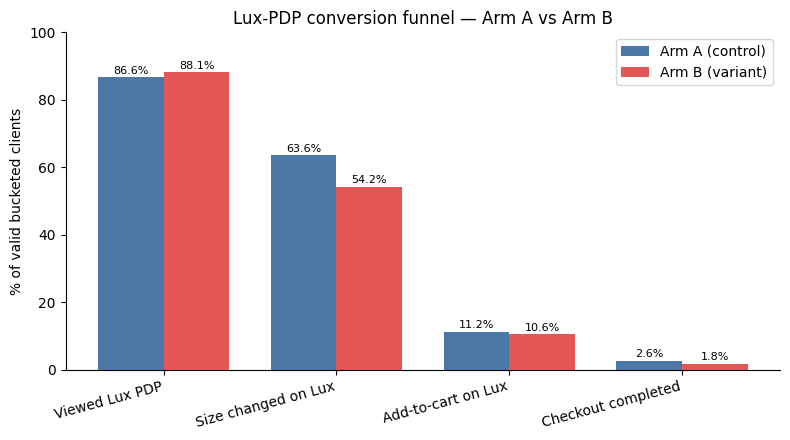

In [4]:
# Funnel visualisation
aPct = [count(m,'a')/baseA*100 for _,m in defs]
bPct = [count(m,'b')/baseB*100 for _,m in defs]
x = np.arange(len(defs)); w = 0.38
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(x-w/2, aPct, w, label='Arm A (control)', color='#4C78A8')
ax.bar(x+w/2, bPct, w, label='Arm B (variant)', color='#E45756')
for i,(va,vb) in enumerate(zip(aPct,bPct)):
    ax.text(i-w/2, va+1, f"{va:.1f}%", ha='center', fontsize=8)
    ax.text(i+w/2, vb+1, f"{vb:.1f}%", ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([l for l,_ in defs], rotation=15, ha='right')
ax.set_ylabel('% of valid bucketed clients'); ax.set_ylim(0,100)
ax.set_title('Lux-PDP conversion funnel — Arm A vs Arm B')
ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

**Step-to-step conditional rates** — the diagnosis lives here. Each row is *P(reach next step | reached the prior step)*, using the baseline's own site-level event definitions so the comparison is apples-to-apples.

In [5]:
STEPS = [('page_viewed','Page view'),('size_changed','Size'),
         ('product_added_to_cart','Add-to-cart'),('checkout_initiated','Checkout init'),
         ('checkout_started','Checkout started'),('checkout_completed','Purchase')]
S = {a:{lbl:cset(d.event_name==evn,a) for evn,lbl in STEPS} for a in ['a','b']}
rows=[]
for i in range(len(STEPS)-1):
    pl,cl = STEPS[i][1], STEPS[i+1][1]
    Ap,Ac = S['a'][pl],S['a'][cl]; Bp,Bc = S['b'][pl],S['b'][cl]
    ad,bd = len(Ap),len(Bp); an,bn = len(Ac&Ap),len(Bc&Bp)
    z,p = ztest(an,ad,bn,bd)
    rows.append([f"{pl} → {cl}", f"{an/ad*100:.1f}%", f"{bn/bd*100:.1f}%",
                 f"{bn/bd*100-an/ad*100:+.1f}", f"{z:.2f}", f"{p:.4f}", "*" if p<0.05 else ""])
pd.DataFrame(rows, columns=['Transition','A','B','Δ pp','z','p','sig'])

,Transition,A,B,Δ pp,z,p,sig
0,Page view → Size,83.3%,72.4%,-10.9,9.43,0.0000,*
1,Size → Add-to-cart,22.7%,24.0%,+1.3,-1.01,0.3142,
2,Add-to-cart → Checkout init,40.8%,32.0%,-8.8,2.84,0.0045,*
3,Checkout init → Checkout started,65.6%,67.1%,+1.4,-0.29,0.7748,
4,Checkout started → Purchase,34.6%,30.6%,-4.1,0.66,0.5065,


Two steps are significant: **Page-view → Size** (−10.9pp) and **Add-to-cart → Checkout-init** (−8.8pp, **p=0.005**). The step *between* them — **Size → Add-to-cart** — is flat/slightly favours B. So the size drop never becomes a conversion drop; a *separate* leak opens at the cart.

**Order-level economics** (below) confirm the loss is **volume**, not basket size: median AOV is identical across arms and revenue-per-user tracks the conversion gap.

In [6]:
cc = d[d.event_name=='checkout_completed'].copy()
cc['order_id'] = pd.to_numeric(cc.event_data.apply(lambda s: jget(s,'order_id')), errors='coerce')
ow = orders.merge(cc[['order_id','arm']].drop_duplicates(), on='order_id', how='inner')
tot = ow.groupby(['order_id','arm']).value.sum().reset_index()
for a in ['a','b']:
    v = tot[tot.arm==a].value; base = baseA if a=='a' else baseB
    print(f"Arm {a.upper()}: {len(v)} orders | AOV mean=${v.mean():,.0f} median=${v.median():,.0f} "
          f"| revenue=${v.sum():,.0f} | rev/user=${v.sum()/base:.2f}")

Arm A: 67 orders | AOV mean=$1,962 median=$1,599 | revenue=$131,429 | rev/user=$52.63
Arm B: 51 orders | AOV mean=$1,909 median=$1,599 | revenue=$97,357 | rev/user=$35.58


## b. The read — what the funnel is telling us

**There are two independent leaks, and only one is about intent.**

- **The size-selection drop is real but inert.** Conditional on viewing the PDP it falls 73.4% → 61.6% (p<0.001), yet users in B who reach the size step add to cart at the *same* rate (`Size → ATC` +1.3pp, n.s.). If size-selection were "the primary driver of lower conversion," the deficit would show here — it doesn't.
- **The deficit appears one step later:** `Add-to-cart → Checkout-initiation`, **40.8% → 32.0% (p=0.005)**. B gets just as many adds to cart, then loses ~9 extra points of them before checkout even starts.

B is not failing to *get users to the buy box* — it reaches slightly **more** users to the PDP. It's failing to *convert intent*: the carts it creates are weaker. This is a **reachability vs. desirability** distinction the raw funnel hides.

## c. Behavioral changes — and why

Two behavioral probes: (1) do B users add to cart *without* engaging the size selector, and (2) does scroll telemetry support the baseline's "buried selector" hypothesis?

In [7]:
# (1) size -> add-to-cart coupling on the Lux PDP
for a in ['a','b']:
    atc = cset((d.event_name=='product_added_to_cart') & is_lux, a)
    sz  = cset((d.event_name=='size_changed')          & is_lux, a)
    both = len(atc & sz)
    print(f"Arm {a.upper()}: {both}/{len(atc)} = {both/len(atc)*100:.1f}% of Lux add-to-carts had a "
          f"size_changed  ->  {100-both/len(atc)*100:.1f}% added with NO size change")

print()
# (2) scroll depth on the Lux PDP
sc = d[(d.event_name=='scroll') & is_lux].copy()
sc['depth'] = pd.to_numeric(sc.event_data.apply(lambda s: jget(s,'scroll_depth_pct')), errors='coerce')
sc['ph']    = pd.to_numeric(sc.event_data.apply(lambda s: jget(s,'page_height')),      errors='coerce')
maxd = sc.groupby(['arm','client_id']).depth.max()
for a in ['a','b']:
    md_ = maxd.loc[a]
    print(f"Arm {a.upper()}: median page_height={sc[sc.arm==a].ph.median():.0f}px | "
          f"median max scroll={md_.median():.0f}% | reached >=50% by {(md_>=50).mean()*100:.1f}% of users")

Arm A: 270/280 = 96.4% of Lux add-to-carts had a size_changed  ->  3.6% added with NO size change


Arm B: 263/289 = 91.0% of Lux add-to-carts had a size_changed  ->  9.0% added with NO size change



Arm A: median page_height=7580px | median max scroll=33% | reached >=50% by 21.4% of users
Arm B: median page_height=9137px | median max scroll=37% | reached >=50% by 31.0% of users


**The size metric three ways** — the drop is robust to scoping, so the *interpretation* (not the number) is what changes:

In [8]:
vA = count((d.event_name=='page_viewed') & is_lux,'a')
vB = count((d.event_name=='page_viewed') & is_lux,'b')
sz = d.event_name=='size_changed'
for t,na,da,nb,db in [
    ("Baseline: size_changed anywhere / all valid",   count(sz,'a'),baseA,        count(sz,'b'),baseB),
    ("Lux: size on PDP / all valid (ITT)",            count(sz&is_lux,'a'),baseA, count(sz&is_lux,'b'),baseB),
    ("Lux: size on PDP / PDP viewers (conditional)",  count(sz&is_lux,'a'),vA,    count(sz&is_lux,'b'),vB)]:
    z,p = ztest(na,da,nb,db)
    print(f"{t:<48} A={na/da*100:5.1f}%  B={nb/db*100:5.1f}%  "
          f"Δ={nb/db*100-na/da*100:+5.1f}pp  z={z:5.2f}  p={p:.2e}")

Baseline: size_changed anywhere / all valid      A= 83.3%  B= 72.4%  Δ=-10.9pp  z= 9.43  p=0.00e+00
Lux: size on PDP / all valid (ITT)               A= 63.6%  B= 54.2%  Δ= -9.3pp  z= 6.84  p=8.12e-12
Lux: size on PDP / PDP viewers (conditional)     A= 73.4%  B= 61.6%  Δ=-11.8pp  z= 8.50  p=0.00e+00


**1. "Size changed" is partly a measurement artifact.** In B, **9.0%** of Lux add-to-carts fired with *no* `size_changed` event (vs **3.6%** in A). Combined with the flat `Size → ATC` rate, the likely mechanism is that **B defaults / pre-selects a size or de-emphasizes the control**, so users don't need to touch it. Fewer `size_changed` events ≠ fewer users choosing a size.

**2. The "buried selector" hypothesis doesn't hold.** B's PDP is **~20% taller** (median 9,137px vs 7,580px) and B users scroll **deeper** (median max 37% vs 33%; ≥50% reached by 31% vs 21%). If the selector were simply pushed below the fold, engagement would fall *with* reach — instead users travel further down the page. The change is to the control's **design/necessity**, not its reachability.

**3. The behavioral change that costs money:** B manufactures **lower-commitment carts**. Same add rate, but a frictionless / default-size add invites tentative adds that reconsider at the (shared) `/cart` page and abandon before checkout. The arm difference is *set* on the PDP but *realized* at the cart.

## d. Recommendation

1. **Do not blanket-revert.** B's loss is concentrated in one diagnosable step, and B actually reaches *more* users to the PDP. A revert discards that gain to fix a mid-funnel problem a targeted change can address.
2. **Fix instrumentation first.** Separate "size selected" (incl. defaults) from "size changed" so the top-funnel metric is trustworthy — today it conflates a UX default with lost engagement, which is what produced the baseline's misdiagnosis.
3. **Target the cart-intent leak.** Test an explicit size confirmation before add-to-cart in B (or surface size/price clearly at the cart) to raise cart quality — that is the `ATC → checkout` step, the only significant *downstream* break.
4. **Re-power and re-read.** Final conversion rests on 66 vs 49 purchases (fragile). Extend the test and evaluate on `ATC → checkout-initiation`, which is significant now and closer to the mechanism. Flag the **SRM** (47.7 / 52.3, p=0.001) to engineering — it doesn't explain B's loss (B had *more* users) but signals a possible bucketing issue.

## Process & AI usage

- **Data exploration** — profiled event types and `page_path` per funnel step (which surfaced the PDP-scoping issue), and validated the placebo-key contamination and traffic-quality consistency.
- **Code generation** — funnel construction, conditional two-proportion z-tests, scroll/JSON parsing, and the chart.
- **Interpretation & pressure-testing** — challenged the baseline's "size-selection is the primary driver" claim by testing whether the size gap propagates; located the real leak at Add-to-cart → Checkout.
- **AI tool:** Claude, via Claude Code, for the above. I reviewed and verified every output and wrote the final read and recommendation myself.

## AI-Delta Log

**Field 1 — Baseline assessment.**
Claude's baseline is mechanically sound: first-touch arm assignment, a valid-traffic filter, a correct SRM flag (χ²=10.92, p=0.001), and a correct order-level read — the loss is volume-driven, not basket-size (median AOV is identical at $1,599). Its direction is right: B converts ~32% worse. But it misses three things. **Scope:** it counts size-changes and add-to-carts across all products, though only the Lux PDP changed — just 60% of size-changes and 30% of add-to-carts happen there, so its headline "size-selection collapse" is measured largely off the redesigned page. **Downstream:** it calls the funnel below add-to-cart "similar" between arms, yet Add-to-cart → Checkout-initiation is significantly worse in B (p=0.005). **Mechanism:** it asserts a "buried selector" without checking scroll telemetry, and treats `size_changed` as pure intent when it is instrumentation-dependent.

**Field 2 — Points of disagreement.**
I disagree that size-selection is "the primary driver of lower conversion." The gap does not propagate: conditional on reaching the size step, B converts to add-to-cart at the same rate (Size → ATC +1.3pp, non-significant). If size drove conversion, the deficit would surface here — it does not. The real leak is one step later: Add-to-cart → Checkout-initiation, 40.8% → 32.0% (p=0.005), which the baseline dismissed as "similar bleed." I also disagree with the blanket "revert to control." It treats a symptom the data does not support, ignores that B reached *more* users to the PDP, and rests the verdict on 66 vs 49 purchases — final conversion is only p≈0.036, statistically fragile. The baseline stopped at absolute funnel rates; the conditional, surface-scoped read tells a materially different story.

**Field 3 — Your analytical additions.**
Four things the baseline lacks. (1) A PDP-scoped funnel that isolates the one surface the experiment changed, removing cross-product contamination. (2) Step-to-step conditional significance that relocates the leak from size-selection to Add-to-cart → Checkout (p=0.005). (3) A mechanism for the size drop: 9.0% of B's Lux add-to-carts fired with no `size_changed` event versus 3.6% in A — largely a measurement/UX-default artifact, not lost intent (a reachability-vs-desirability distinction the baseline never draws). (4) Scroll evidence refuting the "buried selector" guess: B's page is ~20% taller (9,137 vs 7,580px) yet users scroll deeper (≥50% depth reached by 31% vs 21%). My recommendation targets the mechanism — fix instrumentation, test an explicit size confirmation before add-to-cart, preserve B's reach, re-power on ATC → checkout — not a blanket revert.

**Field 4 — AI tools and how you used them.**
Claude (Anthropic), used via Claude Code, was my AI tool. **Code generation:** funnel construction, the conditional two-proportion z-tests, scroll/JSON parsing, and the funnel chart. **Data exploration:** profiling event types and `page_path` to surface the cross-product contamination, plus checking the placebo key and traffic-quality consistency. **Pressure-testing:** challenging the baseline's "size-selection is the primary driver" claim by testing whether the size gap propagates downstream. I reviewed, verified, and wrote the final interpretation and recommendation myself.